In [7]:
import pandas as pd
df=pd.read_csv("downloads/retail_data.csv")

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df.describe()

,Transaction_ID,Customer_ID,Phone,Zipcode,Age,Year,Total_Purchases,Amount,Total_Amount,Ratings
count,3.016770e+05,301702.000000,3.016480e+05,301670.000000,301837.000000,301660.000000,301649.000000,301653.000000,301660.000000,301826.000000
mean,5.495823e+06,55006.553934,5.501464e+09,50298.951019,35.481326,2023.165113,5.359729,255.163659,1367.651156,3.162670
std,2.595565e+06,26005.675200,2.596017e+09,28972.807134,15.021933,0.371283,2.868575,141.389640,1128.998515,1.320827
min,1.000007e+06,10000.000000,1.000049e+09,501.000000,18.000000,2023.000000,1.000000,10.000219,10.003750,1.000000
25%,3.247930e+06,32469.250000,3.255061e+09,25425.000000,22.000000,2023.000000,3.000000,132.890764,438.724278,2.000000
50%,5.499657e+06,55012.000000,5.505812e+09,50602.500000,32.000000,2023.000000,5.000000,255.470969,1041.117547,3.000000
75%,7.739509e+06,77511.000000,7.749860e+09,75252.000000,46.000000,2023.000000,8.000000,377.672606,2029.999853,4.000000
max,9.999995e+06,99999.000000,9.999996e+09,99949.000000,70.000000,2024.000000,10.000000,499.997911,4999.625796,5.000000


In [9]:
df.shape

(302010, 30)

In [10]:
df.columns

Index(['Transaction_ID', 'Customer_ID', 'Name', 'Email', 'Phone', 'Address',
       'City', 'State', 'Zipcode', 'Country', 'Age', 'Gender', 'Income',
       'Customer_Segment', 'Date', 'Year', 'Month', 'Time', 'Total_Purchases',
       'Amount', 'Total_Amount', 'Product_Category', 'Product_Brand',
       'Product_Type', 'Feedback', 'Shipping_Method', 'Payment_Method',
       'Order_Status', 'Ratings', 'products'],
      dtype='str')

In [11]:
df.columns=df.columns.str.strip().str.lower()

In [12]:
df.columns

Index(['transaction_id', 'customer_id', 'name', 'email', 'phone', 'address',
       'city', 'state', 'zipcode', 'country', 'age', 'gender', 'income',
       'customer_segment', 'date', 'year', 'month', 'time', 'total_purchases',
       'amount', 'total_amount', 'product_category', 'product_brand',
       'product_type', 'feedback', 'shipping_method', 'payment_method',
       'order_status', 'ratings', 'products'],
      dtype='str')

In [13]:
df[df.duplicated(keep=False)]

,transaction_id,customer_id,name,email,phone,address,city,state,zipcode,country,...,total_amount,product_category,product_brand,product_type,feedback,shipping_method,payment_method,order_status,ratings,products
181615,4942326.0,25416.0,Pamela Martin,Christine83@gmail.com,6.657934e+09,9851 Myers Tunnel,Leicester,England,57655.0,UK,...,1535.255087,Clothing,Adidas,Jacket,Average,Same-Day,Cash,Pending,2.0,Varsity jacket
182139,3200766.0,49598.0,Mikayla Mueller,Kenneth43@gmail.com,6.980439e+09,716 Joshua Rapids Apt. 790,Bremen,Berlin,64747.0,Germany,...,2450.946762,Grocery,Pepsi,Soft Drink,Bad,Standard,Cash,Pending,1.0,Iced tea
190525,5340129.0,29920.0,Collin Davis,Courtney47@gmail.com,4.087767e+09,371 Cynthia Drives Suite 699,Wollongong,New South Wales,47758.0,Australia,...,2201.568075,Grocery,Pepsi,Soft Drink,Excellent,Express,Cash,Delivered,4.0,Fruit punch
292839,4476510.0,20103.0,Christine Kim,James11@gmail.com,2.383778e+09,8176 Randy Squares Apt. 772,Kitchener,Ontario,7099.0,Canada,...,940.619277,Clothing,Adidas,T-shirt,Bad,Express,Credit Card,Processing,1.0,Off-the-shoulder tee
299759,4476510.0,20103.0,Christine Kim,James11@gmail.com,2.383778e+09,8176 Randy Squares Apt. 772,Kitchener,Ontario,7099.0,Canada,...,940.619277,Clothing,Adidas,T-shirt,Bad,Express,Credit Card,Processing,1.0,Off-the-shoulder tee
301094,5340129.0,29920.0,Collin Davis,Courtney47@gmail.com,4.087767e+09,371 Cynthia Drives Suite 699,Wollongong,New South Wales,47758.0,Australia,...,2201.568075,Grocery,Pepsi,Soft Drink,Excellent,Express,Cash,Delivered,4.0,Fruit punch
301362,4942326.0,25416.0,Pamela Martin,Christine83@gmail.com,6.657934e+09,9851 Myers Tunnel,Leicester,England,57655.0,UK,...,1535.255087,Clothing,Adidas,Jacket,Average,Same-Day,Cash,Pending,2.0,Varsity jacket
301486,3200766.0,49598.0,Mikayla Mueller,Kenneth43@gmail.com,6.980439e+09,716 Joshua Rapids Apt. 790,Bremen,Berlin,64747.0,Germany,...,2450.946762,Grocery,Pepsi,Soft Drink,Bad,Standard,Cash,Pending,1.0,Iced tea


In [14]:
df=df.drop_duplicates()

In [15]:
df[df.duplicated()]

,transaction_id,customer_id,name,email,phone,address,city,state,zipcode,country,...,total_amount,product_category,product_brand,product_type,feedback,shipping_method,payment_method,order_status,ratings,products


In [16]:
df["date"] = pd.to_datetime(df["date"], errors="coerce", format="mixed")


In [17]:
df["age"] = pd.to_numeric(df["age"], errors="coerce")

In [18]:
df["total_amount"]=pd.to_numeric(df["age"], errors="coerce")

In [19]:
df["age"]=df["age"].fillna(df["age"].median())

In [20]:
df["gender"]=df["gender"].fillna("Unknown")

In [21]:
df.isnull().sum()

transaction_id      333
customer_id         308
name                382
email               347
phone               362
address             315
city                248
state               281
zipcode             340
country             271
age                   0
gender                0
income              290
customer_segment    215
date                359
year                350
month               273
time                350
total_purchases     361
amount              356
total_amount        173
product_category    283
product_brand       281
product_type          0
feedback            184
shipping_method     337
payment_method      297
order_status        235
ratings             184
products              0
dtype: int64

In [22]:
df=df.fillna("Unknown")

In [28]:
df["product_category"].value_counts()

product_category
Electronics    71196
Grocery        66784
Clothing       54739
Books          54622
Home Decor     54382
Unknown          283
Name: count, dtype: int64

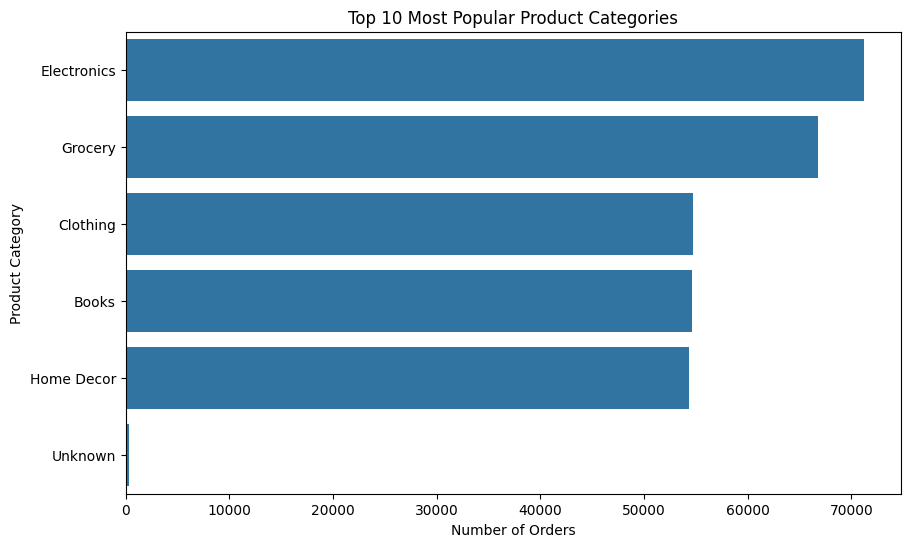

In [59]:
plt.figure(figsize=(10,6))

top_categories = df['product_category'].value_counts().head(10)

sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title("Top 10 Most Popular Product Categories")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")

plt.show()

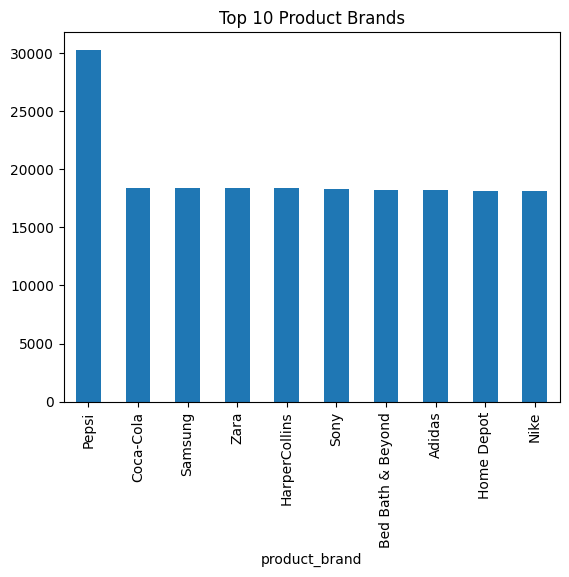

In [60]:
top_brands = df['product_brand'].value_counts().head(10)

top_brands.plot(kind='bar')

plt.title("Top 10 Product Brands")
plt.show()


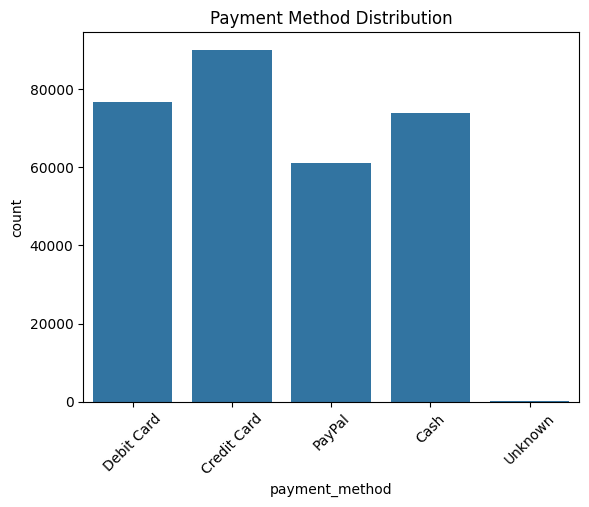

In [71]:
df["payment_method"].value_counts().head(10)
sns.countplot(x="payment_method",data=df)
plt.title("Payment Method Distribution")
plt.xticks(rotation=45)
plt.show()

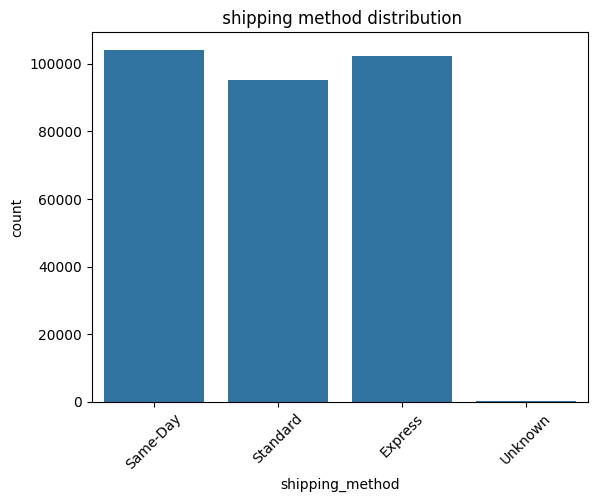

In [72]:
sns.countplot(x='shipping_method', data=df)
plt.title(" shipping method distribution")
plt.xticks(rotation=45)
plt.show()

In [73]:
print(df['ratings'].value_counts().head(10))

ratings
4.0        98063
2.0        62673
5.0        50153
3.0        47636
1.0        43297
Unknown      184
Name: count, dtype: int64


object
[5.0 4.0 2.0 1.0 3.0 'Unknown']


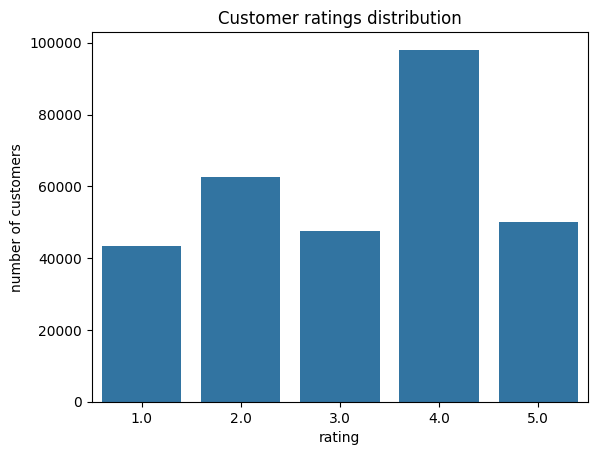

In [78]:
sns.countplot(data=df, x='ratings', order=[1.0, 2.0, 3.0, 4.0, 5.0])
plt.title("Customer ratings distribution")
plt.xlabel("rating")
plt.ylabel("number of customers")
print(df['ratings'].dtype)
print(df['ratings'].unique())

Text(0, 0.5, 'city')

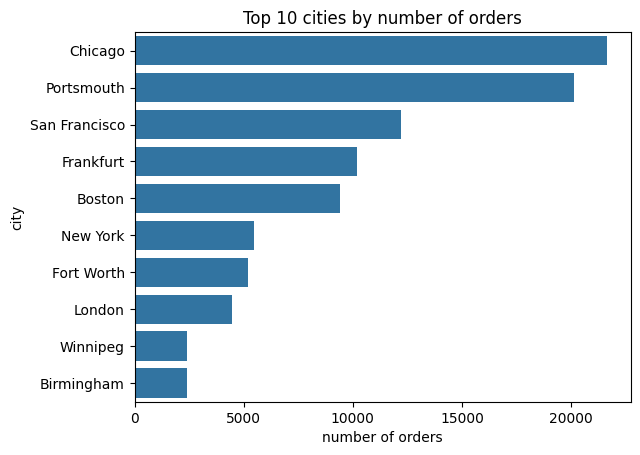

In [80]:
top_cities=df["city"].value_counts().head(10)
sns.barplot(x=top_cities.values,y=top_cities.index)
plt.title("Top 10 cities by number of orders")
plt.xlabel("number of orders")
plt.ylabel("city")

In [81]:
df.to_csv("downloads/retail_clean.csv",index=False)